# 10 — Compare the four saved classifiers

Run 06–09 first, then **Restart Kernel and Run All** here. This notebook verifies and reads their latest completed results. It never fits models, searches parameters, changes cutoffs or reads prepared test rows.

**Declared comparison rule:** highest mean 2025 fold AP; lower fold AP standard deviation and then model name break ties. Later validation is descriptive and does not change this rule. Reused folds and cutoff-selection metrics are exploratory evidence, not independent final tests. Equal trial budgets do not make different search spaces equally exhaustive.

The candidate identified here is not automatically deployed. Your existing dashboard checkpoint and its evidence remain unchanged. Fresh integration of a different classifier requires matching anomaly/SHAP exports and a separate decision.

In [1]:
from pathlib import Path
from importlib import reload
import hashlib
import json
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pricecatcher_config as cfg
cfg = reload(cfg)
MODEL_FOLDERS = {"Logistic Regression": "06_logistic_regression", "Random Forest": "07_random_forest",
                 "XGBoost": "08_xgboost", "LightGBM": "09_lightgbm"}
def file_hash(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()
records = {}
for family, name in MODEL_FOLDERS.items():
    paths = sorted((cfg.PROJECT_ROOT / name).glob("*/study_manifest.json"), reverse=True)
    if not paths:
        raise FileNotFoundError(f"Complete {name} first. Its saved study manifest is missing.")
    path = paths[0]
    manifest = json.loads(path.read_text())
    if manifest.get("status") != "completed" or manifest["selection"]["family"] != family:
        raise ValueError(f"{family}: invalid completed study.")
    for filename, digest in manifest["output_sha256"].items():
        if file_hash(path.parent / filename) != digest:
            raise ValueError(f"{family}: saved output changed: {filename}")
    selection = json.loads((path.parent / "selection.json").read_text())
    if selection != manifest["selection"]:
        raise ValueError(f"{family}: selection does not match its manifest.")
    records[family] = {"folder": path.parent, "manifest": manifest, "selection": selection,
                       "manifest_sha256": file_hash(path)}
reference = next(iter(records.values()))["manifest"]
for family, record in records.items():
    if record["manifest"]["input_sha256"] != reference["input_sha256"]:
        raise ValueError("Studies use different input snapshots. Compare a matching set; do not mix latest runs.")
    if record["selection"]["feature_columns"] != reference["selection"]["feature_columns"]:
        raise ValueError("Model feature lists differ.")
for relative, digest in reference["input_sha256"].items():
    if file_hash(cfg.PROJECT_ROOT / relative) != digest:
        raise ValueError(f"Prepared input changed: {relative}. Restore the study snapshot.")
print("Verified models:", ", ".join(records))

Verified models: Logistic Regression, Random Forest, XGBoost, LightGBM


## Matching rows and metrics

Compare fold selection metrics and separate January–March validation metrics. All selected-cutoff precision/recall/F1 values reuse the cutoff-selection period. Different cutoffs do not imply equal workload or recall. At 0.5, weighting may shift scores and change recall independently of AP.

In [2]:
rows, fold_tables, group_tables = [], [], []
reference_rows = None
keys = ["item_code", "state", "district", "premise_type", "week_start", "next_week_end", "surge_label"]
for family, record in records.items():
    folder = record["folder"]
    summary = pd.read_csv(folder / "fold_summary.csv").set_index("method").loc["Optuna selected"]
    validation = pd.read_csv(folder / "validation_comparison.csv")
    selected = validation.loc[validation.method.eq("Optuna selected: apparent cutoff-selection performance")]
    if len(selected) != 1:
        raise ValueError(f"{family}: expected one selected-cutoff result.")
    selected = selected.iloc[0]
    predictions = pd.read_parquet(folder / "validation_predictions.parquet")
    ids = predictions[keys].sort_values(keys[:-1]).reset_index(drop=True)
    if reference_rows is None:
        reference_rows = ids
    else:
        pd.testing.assert_frame_equal(reference_rows, ids)
    if not np.isfinite(predictions.model_score).all() or not predictions.model_score.between(0, 1).all():
        raise ValueError("Invalid saved model scores.")
    if len(predictions) != int(selected.rows) or int(predictions.surge_label.sum()) != int(selected.positives):
        raise ValueError("Prediction support and metric tables disagree.")
    rows.append({"model": family, "mean_fold_ap": summary.mean_ap, "std_fold_ap": summary.std_ap,
                 "validation_ap": selected.average_precision, "cutoff": selected.cutoff,
                 "precision": selected.precision, "recall": selected.recall, "f1": selected.f1,
                 "alerts": int(selected.alerts), "tp": int(selected.tp), "fp": int(selected.fp), "fn": int(selected.fn),
                 "validation_rows": int(selected.rows), "positives": int(selected.positives)})
    folds = pd.read_csv(folder / "fold_comparison.csv")
    folds = folds.loc[folds.method.eq("Optuna selected")].copy()
    folds["model"] = family
    fold_tables.append(folds)
    groups = pd.read_csv(folder / "validation_group_metrics.csv")
    groups["model"] = family
    group_tables.append(groups)
comparison = pd.DataFrame(rows).sort_values(["mean_fold_ap", "std_fold_ap", "model"], ascending=[False, True, True])
selected_family = comparison.iloc[0]["model"]
fold_comparison = pd.concat(fold_tables, ignore_index=True)
group_comparison = pd.concat(group_tables, ignore_index=True)
display(comparison)
print("Candidate under the declared fold rule:", selected_family)
print("No dashboard replacement or independent-test claim follows from this comparison.")

,model,mean_fold_ap,std_fold_ap,validation_ap,cutoff,precision,recall,f1,alerts,tp,fp,fn,validation_rows,positives
3,LightGBM,0.359971,0.066703,0.216171,0.159058,0.228860,0.660020,0.339871,11282,2582,8700,1330,43594,3912
2,XGBoost,0.356186,0.060585,0.224896,0.140662,0.226942,0.733384,0.346623,12642,2869,9773,1043,43594,3912
1,Random Forest,0.348595,0.069108,0.250297,0.195624,0.237423,0.640593,0.346444,10555,2506,8049,1406,43594,3912
0,Logistic Regression,0.303335,0.031596,0.248489,0.210914,0.261194,0.518916,0.347484,7772,2030,5742,1882,43594,3912


Candidate under the declared fold rule: LightGBM
No dashboard replacement or independent-test claim follows from this comparison.


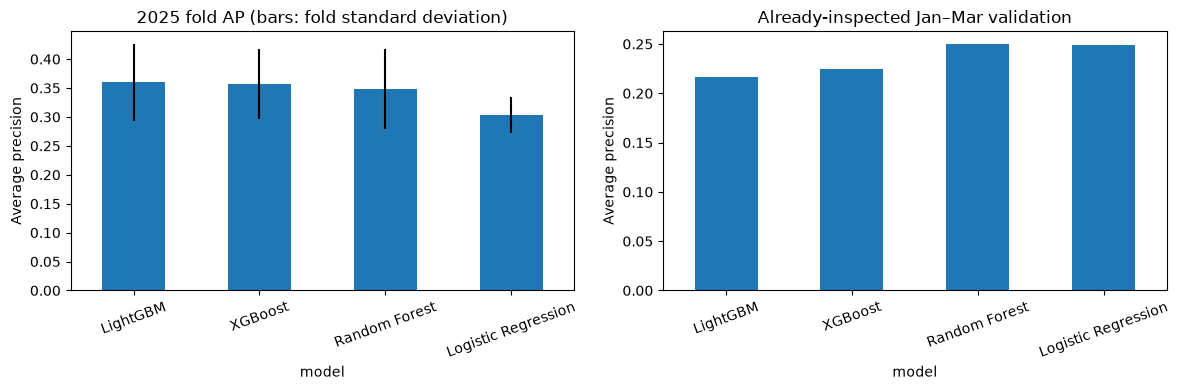

Saved comparison: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/10_model_comparison/20261027_163247_368591


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
comparison.plot.bar(x="model", y="mean_fold_ap", yerr="std_fold_ap", legend=False, ax=axes[0], rot=20)
axes[0].set(title="2025 fold AP (bars: fold standard deviation)", ylabel="Average precision")
comparison.plot.bar(x="model", y="validation_ap", legend=False, ax=axes[1], rot=20)
axes[1].set(title="Already-inspected Jan–Mar validation", ylabel="Average precision")
fig.tight_layout()
plt.show()
# Verify source studies again before saving a new, separate comparison.
for record in records.values():
    if file_hash(record["folder"] / "study_manifest.json") != record["manifest_sha256"]:
        raise ValueError("A source study changed during comparison.")
output = cfg.PROJECT_ROOT / "10_model_comparison" / datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
output.mkdir(parents=True, exist_ok=False)
comparison.to_csv(output / "model_comparison.csv", index=False)
fold_comparison.to_csv(output / "fold_comparison.csv", index=False)
group_comparison.to_csv(output / "group_comparison.csv", index=False)
fig.savefig(output / "model_comparison.png", dpi=160, bbox_inches="tight")
manifest = {"status": "completed", "candidate_under_fold_rule": selected_family,
            "deployment_changed": False, "test_evaluated": False,
            "rule": "mean fold AP descending; fold AP standard deviation ascending; model name ascending",
            "studies": {k: {"folder": str(v["folder"].relative_to(cfg.PROJECT_ROOT)),
                             "manifest_sha256": v["manifest_sha256"]} for k, v in records.items()},
            "output_sha256": {p.name: file_hash(p) for p in output.iterdir()}}
(output / "comparison_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved comparison:", output)

## Report interpretation

Present each technique in its model notebook, then use this table for the combined discussion. Include reference-versus-tuned results within each model, baseline comparisons, temporal variation, group support, false alerts and missed surges. Do not present the largest number as universal superiority. Fold standard deviation is not a confidence interval. Saved package versions identify implementation differences.

The existing longer-history dashboard is a separate experiment. Its original reference checkpoint is stored independently of the retired combined notebook. Opening that dashboard needs no retraining. Stages 11–13 use those saved artifacts; a new run without them does not yet constitute an integrated replacement dashboard. Before deploying a different candidate, regenerate and verify its matching explanations/exports and report its own evaluation evidence.